# Projet CVRIE - Supervised Learning (Analyse Radiographique)
**Analyse d'images médicales pour la détection de pneumonies.**

## Les imports

In [ ]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

## Chargement des données

In [ ]:
X_liste = []
y_liste = []
nombre_normal = 0
nombre_pneumonia = 0

def ouvrir_fichier(chemin_dossier, label):
    if not os.path.exists(chemin_dossier):
        sys.stderr.write("Erreur : dossier introuvable !")
        sys.exit(84)
    for fichier in os.listdir(chemin_dossier):
        if not fichier.lower().endswith((".jpeg", ".jpg", ".png")):
            continue
        chemin_complet = os.path.join(chemin_dossier, fichier)
        try:
            image_save = Image.open(chemin_complet)
            image_save = image_save.convert("L")
            image_save = image_save.resize((64, 64))
            image_chiffre = np.array(image_save)
            image_applatie = image_chiffre.flatten()
            X_liste.append(image_applatie)
            y_liste.append(label)
        except Exception as error:
            sys.stderr.write(f"Erreur de lecture ! {error}")
            sys.exit(84)

ouvrir_fichier("../data/chest_xray/train/NORMAL", 0)
ouvrir_fichier("../data/chest_xray/test/NORMAL", 0)
ouvrir_fichier("../data/chest_xray/val/NORMAL", 0)

ouvrir_fichier("../data/chest_xray/train/PNEUMONIA", 1)
ouvrir_fichier("../data/chest_xray/test/PNEUMONIA", 1)
ouvrir_fichier("../data/chest_xray/val/PNEUMONIA", 1)

X = np.array(X_liste)
y = np.array(y_liste)

## Data pre-processing
Avant d'entraîner notre modèle, nous analysons la répartition des données. Nous observons un fort déséquilibre entre les classes saines et malades. Cela justifie l'utilisation de l'argument `stratify=y` lors de la séparation des données pour garantir une répartition proportionnelle dans nos échantillons d'entraînement et de test.

In [ ]:
nombre_normal = np.sum(y == 0)
nombre_pneumonia = np.sum(y == 1)

labels = ["NORMAL", "PNEUMONIA"]
values = [nombre_normal, nombre_pneumonia]

plt.bar(labels, values, width=0.6, color=['#4C72B0', '#C44E52'])
plt.title("Nombre de NORMAL vs PNEUMONIA")
plt.ylabel("Nombre d'images")
plt.show()

## Model comparisons
Dans un premier temps, nous utilisons un algorithme de type Random Forest (Forêt aléatoire) pour effectuer notre classification binaire.

Précision globale : 0.9565

              precision    recall  f1-score   support

      NORMAL       0.96      0.88      0.92       317
   PNEUMONIA       0.96      0.98      0.97       855

    accuracy                           0.96      1172
   macro avg       0.96      0.93      0.94      1172
weighted avg       0.96      0.96      0.96      1172



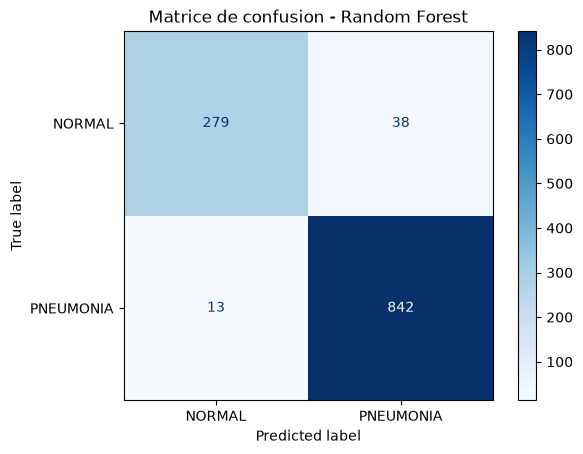

In [43]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=458, stratify=y
)

modele = RandomForestClassifier(random_state=455)
modele.fit(X_train, y_train)

predictions = modele.predict(X_test)
print(f"Précision globale : {accuracy_score(y_test, predictions):.4f}\n")
print(classification_report(y_test, predictions, target_names=["NORMAL", "PNEUMONIA"]))

disp = ConfusionMatrixDisplay.from_estimator(
    modele,
    X_test,
    y_test,
    display_labels=["NORMAL", "PNEUMONIA"],
    cmap=plt.cm.Blues
)
plt.title("Matrice de confusion - Random Forest")
plt.show()

## Loss function explanation

## Conclusions and insight
Sur l'échantillon de test (1172 patients) :
- Le taux de faux négatifs (pneumonie ratée, classée NORMAL) est d'environ 1.5%. Ce chiffre extrêmement faible est un très bon point dans un contexte médical où renvoyer un malade chez lui (faux négatif) est dangereux.
- Le taux de faux positifs (patient sain classé PNEUMONIA) est d'environ 12%. Le modèle est donc plutôt prudent, ce qui implique que quelques patients sains seront envoyés pour des examens complémentaires.